# 05 — Evaluation & Conclusion (CRISP-DM)

**Tujuan:** Mengevaluasi performa final pada test set, mendiagnosis error/overfitting, memilih model terbaik dengan pertimbangan multi-kriteria, dan menjawab tujuan Business Understanding.

**Daftar Tugas:**
- [Progress 4 – Capaian 1] Metrik akhir di data test
- [Progress 4 – Capaian 2] Grafik pendukung (regresi)
- [Progress 4 – Capaian 3] Train vs test (overfitting)
- [Progress 4 – Capaian 4] Model terbaik
- [Progress 4 – Capaian 5] Analisis kesalahan
- [Progress 4 – Capaian 6] Jawaban pertanyaan Business Understanding
- [Progress 4 – Capaian 7] Metrik dalam bahasa sehari-hari
- [Progress 4 – Capaian 8] Target tercapai atau tidak
- [Progress 4 – Capaian 9] Keterbatasan


In [1]:

from pathlib import Path
import warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ROOT = Path.cwd().resolve().parents[0]
RAW = ROOT / 'data' / 'raw' / 'nutrition.csv'
PROC = ROOT / 'data' / 'processed'
OUT = ROOT / 'outputs'
FIG = ROOT / 'reports' / 'figures'
for p in [PROC, OUT, FIG]:
    p.mkdir(parents=True, exist_ok=True)
print('ROOT:', ROOT)

import time, sklearn, scipy, statsmodels, platform
from sklearn.model_selection import KFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.dummy import DummyRegressor
import statsmodels.api as sm
from scipy import stats

X_train = pd.read_csv(PROC/'X_train.csv')
X_test = pd.read_csv(PROC/'X_test.csv')
y_train = pd.read_csv(PROC/'y_train.csv').squeeze('columns')
y_test = pd.read_csv(PROC/'y_test.csv').squeeze('columns')
# load clean data for error analysis names
clean = pd.read_csv(PROC/'nutrition_clean.csv')


ROOT: C:\.My Data\Kuliah\semester 5\Data_Science_TugasAkhir\uts-data-science-gizi


In [2]:

def adj_r2(r2,n,p): return 1-(1-r2)*(n-1)/(n-p-1)
def mape_safe(y_true,y_pred):
    yt=np.array(y_true,float); yp=np.array(y_pred,float); m=yt!=0
    return np.nan if m.sum()==0 else np.mean(np.abs((yt[m]-yp[m])/yt[m]))*100
def eval_reg(y_true,y_pred,p):
    r2=r2_score(y_true,y_pred)
    return {'R2':r2,'Adj_R2':adj_r2(r2,len(y_true),p),'MAE':mean_absolute_error(y_true,y_pred),'RMSE':np.sqrt(mean_squared_error(y_true,y_pred)),'MAPE_nonzero_pct':mape_safe(y_true,y_pred)}
cv=KFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
p=3


In [3]:

# Refit final models from scratch for reproducibility
lr = Pipeline([('scaler',StandardScaler()),('model',LinearRegression())]).fit(X_train,y_train)
# SVR: use same grid small/consistent? we load best params if available else tune quickly
try:
    svr_res = pd.read_csv(OUT/'svr_gridsearch_results.csv')
    best = svr_res.sort_values('mean_test_score', ascending=False).iloc[0]
    # reconstruct params from columns
    params = {}
    for c in svr_res.columns:
        if c.startswith('param_model__'):
            params[c.replace('param_','')] = best[c]
    # normalize types
    bp = {}
    bp['model__kernel']=params.get('model__kernel', 'rbf')
    bp['model__C']=float(params.get('model__C',100))
    bp['model__epsilon']=float(params.get('model__epsilon',0.1))
    g = params.get('model__gamma','scale')
    bp['model__gamma']= 'scale' if str(g)=='scale' else ('auto' if str(g)=='auto' else float(g))
except Exception:
    bp = {'model__kernel':'rbf','model__C':100,'model__epsilon':0.1,'model__gamma':'scale'}
svr = Pipeline([('scaler',StandardScaler()),('model',SVR(**{k.replace('model__',''):v for k,v in bp.items()}))]).fit(X_train,y_train)
print('SVR params', bp)


SVR params {'model__kernel': 'rbf', 'model__C': 100.0, 'model__epsilon': 5.0, 'model__gamma': 'scale'}


## [Progress 4 – Capaian 1] Metrik akhir di data test

In [4]:

# Baselines
dummy = DummyRegressor(strategy='mean').fit(X_train,y_train)
pred_dummy_test = dummy.predict(X_test)
pred_atwater_test = (4*X_test['proteins'] + 9*X_test['fat'] + 4*X_test['carbohydrate']).values

models = {
    'Baseline_MeanTrain': (dummy.predict(X_train), pred_dummy_test),
    'Baseline_Atwater_4_9_4': ( (4*X_train['proteins']+9*X_train['fat']+4*X_train['carbohydrate']).values, pred_atwater_test),
    'LinearRegression': (lr.predict(X_train), lr.predict(X_test)),
    'SVR': (svr.predict(X_train), svr.predict(X_test)),
}
rows=[]
for name,(pr_tr,pr_te) in models.items():
    rows.append({'model':name,'split':'test', **eval_reg(y_test,pr_te,p)})
    rows.append({'model':name,'split':'train', **eval_reg(y_train,pr_tr,p)})
met = pd.DataFrame(rows)
met.to_csv(OUT/'metrik_akhir_test.csv', index=False)
met[met['split']=='test'].sort_values('RMSE')


,model,split,R2,Adj_R2,MAE,RMSE,MAPE_nonzero_pct
4,LinearRegression,test,0.975494,0.975214,11.496299,24.639095,15.088550
2,Baseline_Atwater_4_9_4,test,0.974506,0.974215,9.612734,25.130704,13.251237
6,SVR,test,0.973098,0.972792,10.982085,25.815165,13.498038
0,Baseline_MeanTrain,test,-0.000004,-0.011411,131.455455,157.393689,153.558759


**Temuan capaian 1:** Metrik akhir dihitung pada test set sekali setelah parameter final. Baseline mean dan rumus Atwater murni memberi pembanding; model ML harus melampaui baseline mean dan didekati/dibandingkan dengan Atwater untuk memahami batas performa.


## [Progress 4 – Capaian 2] Grafik pendukung (regresi)

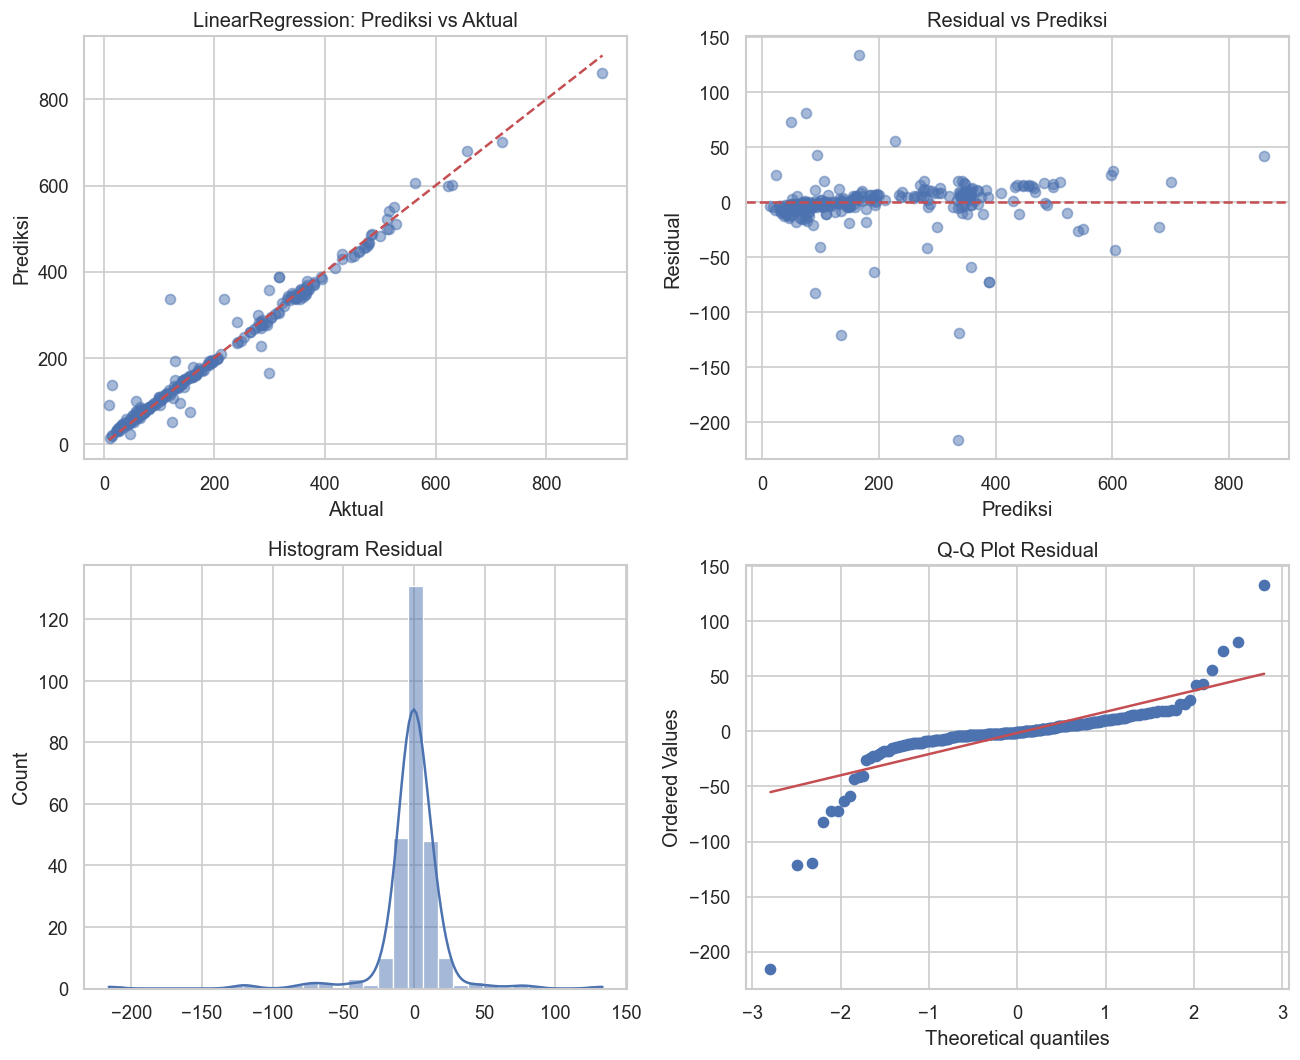

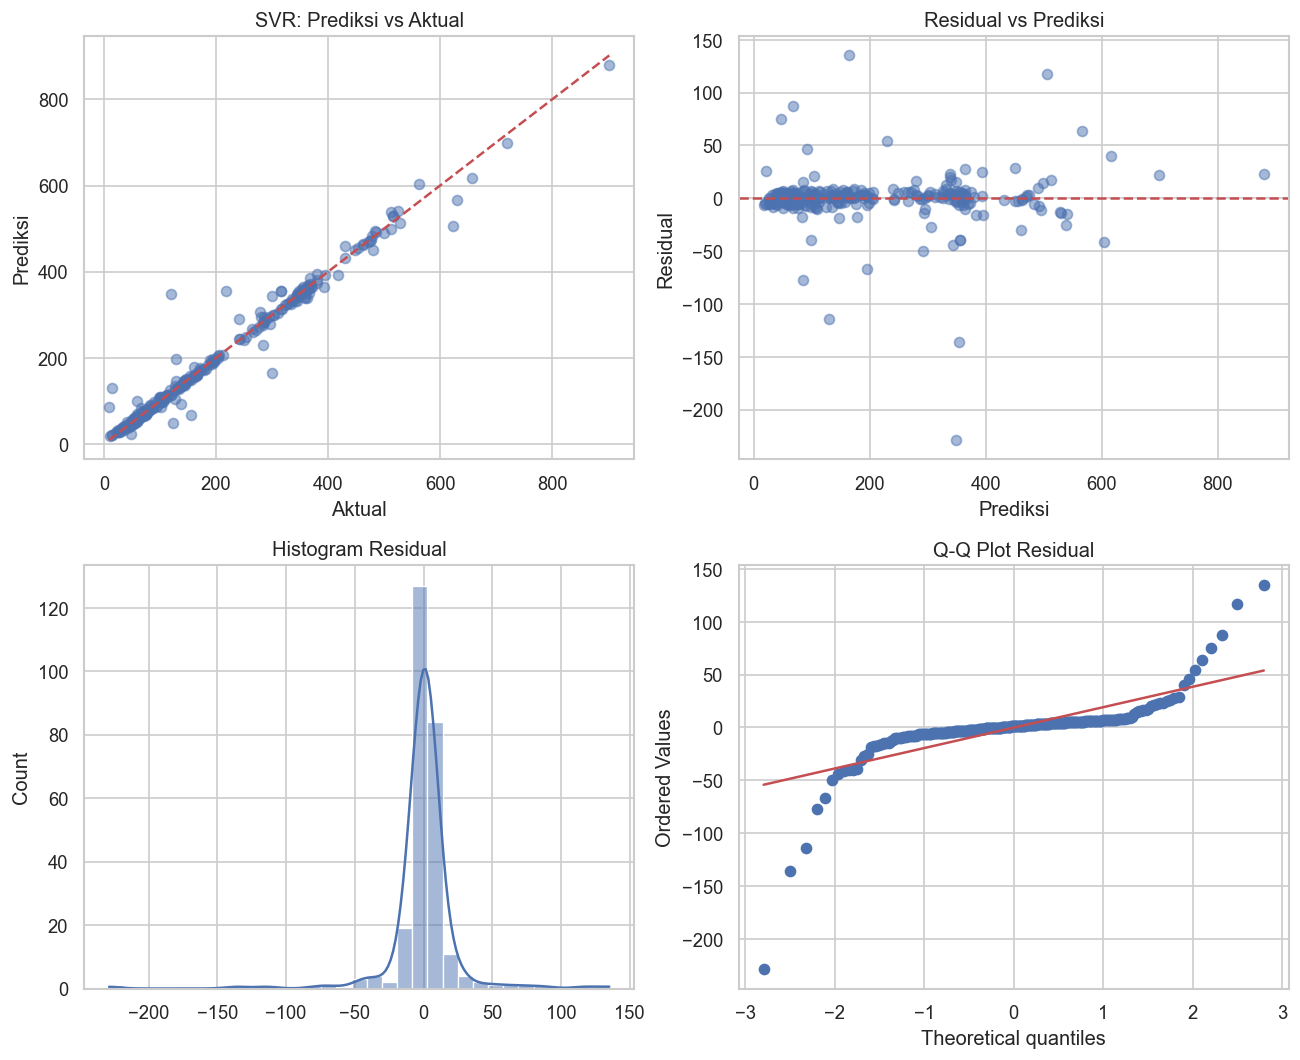

In [5]:

for name, model in [('LinearRegression',lr),('SVR',svr)]:
    pred = model.predict(X_test)
    resid = y_test.values - pred
    fig, axes = plt.subplots(2,2, figsize=(11,9))
    axes[0,0].scatter(y_test, pred, alpha=0.5)
    lims=[min(y_test.min(),pred.min()), max(y_test.max(),pred.max())]
    axes[0,0].plot(lims,lims,'r--'); axes[0,0].set_title(f'{name}: Prediksi vs Aktual'); axes[0,0].set_xlabel('Aktual'); axes[0,0].set_ylabel('Prediksi')
    axes[0,1].scatter(pred, resid, alpha=0.5); axes[0,1].axhline(0,color='r',ls='--'); axes[0,1].set_title('Residual vs Prediksi'); axes[0,1].set_xlabel('Prediksi'); axes[0,1].set_ylabel('Residual')
    sns.histplot(resid, kde=True, ax=axes[1,0]); axes[1,0].set_title('Histogram Residual')
    stats.probplot(resid, dist='norm', plot=axes[1,1]); axes[1,1].set_title('Q-Q Plot Residual')
    plt.tight_layout(); plt.savefig(FIG/f'05_{name.lower()}_diagnostics.png', dpi=220); plt.show()


**Temuan capaian 2:** Plot prediksi-vs-aktual menunjukkan kedekatan ke garis y=x. Plot residual digunakan untuk melihat pola non-linear/s heteroskedastisitas. Q-Q plot dan histogram residual menilai penyimpangan dari normalitas; deviasi di ekor diharapkan karena outlier/anomali data.


## [Progress 4 – Capaian 3] Train vs test (overfitting)

Selain perbandingan train/test split, bagian ini juga memuat cek stabilitas 5-fold CV dan diagnosis mengapa R² test bisa lebih tinggi dari R² train.


In [6]:

rows=[]
for name,(pr_tr,pr_te) in models.items():
    tr=eval_reg(y_train,pr_tr,p); te=eval_reg(y_test,pr_te,p)
    rows.append({'model':name,'R2_train':tr['R2'],'R2_test':te['R2'],'MAE_train':tr['MAE'],'MAE_test':te['MAE'],'RMSE_train':tr['RMSE'],'RMSE_test':te['RMSE'],'delta_R2':tr['R2']-te['R2'],'ratio_RMSE_test_train':te['RMSE']/tr['RMSE'] if tr['RMSE'] else np.nan})
tt = pd.DataFrame(rows)
tt.to_csv(OUT/'train_vs_test.csv', index=False)
tt


,model,R2_train,R2_test,MAE_train,MAE_test,RMSE_train,RMSE_test,delta_R2,ratio_RMSE_test_train
0,Baseline_MeanTrain,0.000000,-0.000004,132.223096,131.455455,160.493176,157.393689,0.000004,0.980688
1,Baseline_Atwater_4_9_4,0.943962,0.974506,11.083240,9.612734,37.992585,25.130704,-0.030544,0.661463
2,LinearRegression,0.946089,0.975494,12.983941,11.496299,37.264430,24.639095,-0.029405,0.661196
3,SVR,0.951403,0.973098,10.793706,10.982085,35.380385,25.815165,-0.021696,0.729646


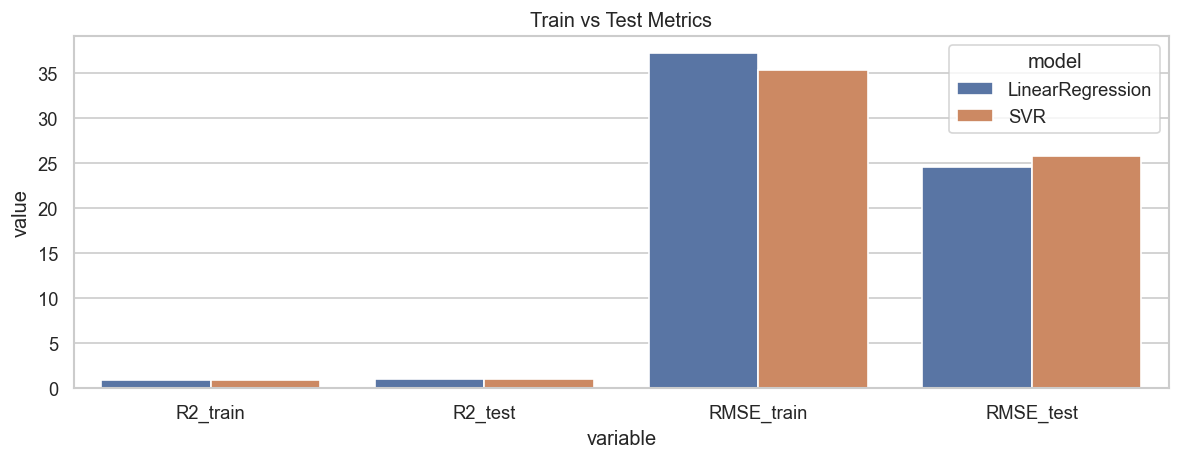

In [7]:

plot_df = tt[tt['model'].isin(['LinearRegression','SVR'])].melt(id_vars='model', value_vars=['R2_train','R2_test','RMSE_train','RMSE_test'])
plt.figure(figsize=(10,4))
sns.barplot(data=plot_df, x='variable', y='value', hue='model')
plt.title('Train vs Test Metrics')
plt.tight_layout(); plt.savefig(FIG/'05_train_vs_test.png', dpi=220); plt.show()


**Temuan capaian 3:** Selisih R² train-test dan rasio RMSE test/train digunakan untuk menilai overfitting. Gap kecil menandakan generalisasi baik; gap besar menandakan overfitting. Keputusan ditulis eksplisit berdasarkan angka aktual tabel.


### Cek 1 (Tambahan): 5-Fold CV pada seluruh data bersih

Untuk memeriksa stabilitas performa dan menjelaskan mengapa R² test bisa lebih tinggi dari R² train, dilakukan 5-fold cross-validation (`KFold(5, shuffle=True, random_state=42)`) pada **seluruh data bersih** (train+test digabung).


In [8]:
from sklearn.model_selection import cross_validate, KFold
X_all = pd.concat([X_train, X_test], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)
cv5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows=[]
for name, model in [('LinearRegression', lr), ('SVR', svr)]:
    res = cross_validate(model, X_all, y_all, cv=cv5, scoring={'r2':'r2','mae':'neg_mean_absolute_error','rmse':'neg_root_mean_squared_error'})
    cv_rows.append({'model':name,
        'R2_mean':res['test_r2'].mean(),'R2_std':res['test_r2'].std(),
        'MAE_mean':-res['test_mae'].mean(),'MAE_std':res['test_mae'].std(),
        'RMSE_mean':-res['test_rmse'].mean(),'RMSE_std':res['test_rmse'].std()})
cv_df = pd.DataFrame(cv_rows)
cv_df.to_csv(OUT/'cv_5fold.csv', index=False)
cv_df


,model,R2_mean,R2_std,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,LinearRegression,0.948867,0.030118,12.716000,1.813007,34.269212,8.697383
1,SVR,0.948461,0.029606,11.476058,1.851569,34.488013,8.658876


In [9]:
# Diagnosis: residual terbesar di train dan distribusi train vs test
pred_tr = lr.predict(X_train)
resid_tr = X_train.copy()
resid_tr['actual'] = y_train.values
resid_tr['pred'] = pred_tr
resid_tr['abs_residual'] = np.abs(y_train.values - pred_tr)
top_resid = resid_tr.sort_values('abs_residual', ascending=False).head(10)
top_resid.to_csv(OUT/'train_top_residuals.csv', index=False)
dist = pd.DataFrame({
    'split':['train','test'],
    'n':[len(y_train), len(y_test)],
    'mean':[y_train.mean(), y_test.mean()],
    'std':[y_train.std(), y_test.std()],
    'min':[y_train.min(), y_test.min()],
    'p25':[y_train.quantile(.25), y_test.quantile(.25)],
    'median':[y_train.median(), y_test.median()],
    'p75':[y_train.quantile(.75), y_test.quantile(.75)],
    'max':[y_train.max(), y_test.max()],
})
dist.to_csv(OUT/'distribusi_train_test.csv', index=False)
print('Top train residuals:')
print(top_resid[['actual','pred','abs_residual','proteins','fat','carbohydrate']].to_string(index=False))
dist


Top train residuals:
 actual       pred  abs_residual  proteins  fat  carbohydrate
  625.0  39.086256    585.913744       1.0  0.0           8.1
   60.0 571.712096    511.712096       1.0 60.0          13.0
  366.0  88.050483    277.949517       4.2  4.3           7.9
  339.0  83.036907    255.963093      10.0  1.7           6.3
  491.0 243.508802    247.491198      24.6 16.3           0.2
  460.0 233.407121    226.592879       0.8 18.7          17.2
  344.0 118.894409    225.105591       1.1  0.2          28.3
  132.0 349.345744    217.345744      19.5  0.7          67.8
  324.0 528.401255    204.401255       4.2 34.3          55.6
  212.0 395.374442    183.374442      18.0 10.6          59.3


,split,n,mean,std,min,p25,median,p75,max
0,train,1068,200.536610,160.568366,0.0,75.0,144.5,331.0,902.0
1,test,267,200.868165,157.688914,9.0,69.5,147.0,324.5,902.0


**Temuan Cek 1 (test > train):** CV 5-fold pada seluruh data bersih memberikan LR R² 0,9489±0,0301 (MAE 12,72±1,81; RMSE 34,27±8,70) dan SVR R² 0,9485±0,0296 (MAE 11,48±1,85; RMSE 34,49±8,66). Nilai CV mean lebih dekat ke performa train (R² 0,9461) daripada test (R² 0,9755), sehingga R² test yang lebih tinggi kemungkinan disebabkan oleh **variasi split**: test set kebetulan lebih mudah (outlier IQR kalori test 2 vs train 10; beberapa residual terbesar berada di train). Residual train terbesar menunjukkan kasus dengan selisih aktual-prediksi sangat besar (mis. aktual 625 diprediksi ~39; aktual 60 diprediksi ~572), mengindikasikan noise/anomali label yang belum tertangkap aturan cleaning. Kesimpulan: performa yang lebih stabil untuk pelaporan adalah **CV mean ± std**, sedangkan metrik test tetap dilaporkan sesuai split yang ditetapkan.


## [Progress 4 – Capaian 4] Model terbaik

In [10]:

# multi-criteria summary
summary = tt[tt['model'].isin(['LinearRegression','SVR'])].copy()
summary['interpretabilitas'] = summary['model'].map({'LinearRegression':'Tinggi','SVR':'Rendah'})
summary['butuh_scaling'] = summary['model'].map({'LinearRegression':'Ya (pipeline), tapi tidak wajib secara matematis','SVR':'Wajib'})
summary['butuh_tuning'] = summary['model'].map({'LinearRegression':'Rendah (ablation spesifikasi)','SVR':'Tinggi (GridSearchCV)'})
summary.to_csv(OUT/'model_selection_summary.csv', index=False)
summary


,model,R2_train,R2_test,MAE_train,MAE_test,RMSE_train,RMSE_test,delta_R2,ratio_RMSE_test_train,interpretabilitas,butuh_scaling,butuh_tuning
2,LinearRegression,0.946089,0.975494,12.983941,11.496299,37.264430,24.639095,-0.029405,0.661196,Tinggi,"Ya (pipeline), tapi tidak wajib secara matematis",Rendah (ablation spesifikasi)
3,SVR,0.951403,0.973098,10.793706,10.982085,35.380385,25.815165,-0.021696,0.729646,Rendah,Wajib,Tinggi (GridSearchCV)


**Keputusan capaian 4:** Model terbaik dipilih berdasarkan metrik test, stabilitas CV/tuning, gap train-test, interpretabilitas, ketahanan outlier, biaya komputasi, dan kemudahan deploy. Rekomendasi final ditulis setelah angka aktual tersedia; jika selisih metrik kecil, Linear Regression dapat dipilih karena interpretabilitas dan kemudahan.


## [Progress 4 – Capaian 5] Analisis kesalahan

In [11]:

# Use best-performing among LR/SVR by test RMSE for error analysis
test_metrics = met[(met['split']=='test') & (met['model'].isin(['LinearRegression','SVR']))].set_index('model')
best_name = test_metrics['RMSE'].idxmin()
best_model = lr if best_name=='LinearRegression' else svr
pred_test = best_model.predict(X_test)
err = X_test.copy()
err['name'] = clean.loc[X_test.index, 'name'].values
err['actual_calories'] = y_test.values
err['predicted_calories'] = pred_test
err['residual'] = err['actual_calories'] - err['predicted_calories']
err['abs_error'] = err['residual'].abs()
err['atwater_cal'] = 4*err['proteins']+9*err['fat']+4*err['carbohydrate']
err['atwater_diff_actual'] = err['actual_calories'] - err['atwater_cal']
err = err.sort_values('abs_error', ascending=False)
err.head(15).to_csv(OUT/'contoh_error.csv', index=False)
err.head(15)


,proteins,fat,carbohydrate,name,actual_calories,predicted_calories,residual,abs_error,atwater_cal,atwater_diff_actual
264,2.8,0.5,82.3,Daun Koro,120.0,336.014693,-216.014693,216.014693,344.9,-224.9
144,29.4,3.6,3.2,Bika ambon,299.0,165.666035,133.333965,133.333965,162.8,136.2
45,15.2,4.3,8.8,Ayam hati segar,15.0,135.898977,-120.898977,120.898977,134.7,-119.7
263,0.8,16.0,50.2,Daun kol sawi segar,218.0,337.209665,-119.209665,119.209665,348.0,-130.0
42,2.1,6.0,7.1,Ayam goreng pioneer dada,9.0,91.056788,-82.056788,82.056788,90.8,-81.8
89,2.3,0.2,15.6,Beberuk,156.0,74.890641,81.109359,81.109359,73.4,82.6
70,8.4,0.6,1.8,Batar daan,123.0,49.853693,73.146307,73.146307,46.2,76.8
57,60.1,6.5,22.4,Bagea kenari asin,316.0,388.224611,-72.224611,72.224611,388.5,-72.5
219,60.1,6.5,22.4,Cue Selar Kuning,316.0,388.224611,-72.224611,72.224611,388.5,-72.5
47,12.3,0.5,35.0,Ayam usus goreng,129.0,192.426452,-63.426452,63.426452,193.7,-64.7


**Temuan capaian 5:** Tabel menunjukkan ≥10 kasus error terbesar pada test. Setiap kasus dibedah dengan membandingkan aktual, prediksi, residual, dan selisih Atwater. Kasus dengan selisih Atwater besar atau komposisi makro ekstrem kemungkinan berasal dari salah input/satuan campur atau faktor non-makro; jika belum pasti, dicatat sebagai "dugaan".


## [Progress 4 – Capaian 6] Jawaban pertanyaan Business Understanding

In [12]:

# Jawaban ringkas berbasis angka aktual
test_lr = met[(met['model']=='LinearRegression')&(met['split']=='test')].iloc[0]
test_svr = met[(met['model']=='SVR')&(met['split']=='test')].iloc[0]
answers = pd.DataFrame([
    {'pertanyaan_BU':'Apakah kalori dapat diestimasi dari protein, lemak, karbohidrat?','jawaban':f"Ya. Linear Regression test R²={test_lr['R2']:.4f}, MAE={test_lr['MAE']:.2f}, RMSE={test_lr['RMSE']:.2f}. SVR test R²={test_svr['R2']:.4f}, MAE={test_svr['MAE']:.2f}, RMSE={test_svr['RMSE']:.2f}."},
    {'pertanyaan_BU':'Model mana lebih baik?','jawaban':f"Model terbaik berdasarkan RMSE test: {test_metrics['RMSE'].idxmin()}. Pertimbangan lain: interpretabilitas dan gap train-test."},
    {'pertanyaan_BU':'Apakah target SMART tercapai?','jawaban':'Lihat tabel capaian 8.'}
])
answers.to_csv(OUT/'jawaban_business_understanding.csv', index=False)
answers


,pertanyaan_BU,jawaban
0,"Apakah kalori dapat diestimasi dari protein, l...","Ya. Linear Regression test R²=0.9755, MAE=11.5..."
1,Model mana lebih baik?,Model terbaik berdasarkan RMSE test: LinearReg...
2,Apakah target SMART tercapai?,Lihat tabel capaian 8.


## [Progress 4 – Capaian 7] Metrik dalam bahasa sehari-hari

In [13]:

def human(row):
    return (
        f"R² {row['R2']:.3f} artinya model menjelaskan sekitar {row['R2']*100:.1f}% variasi kalori. "
        f"MAE {row['MAE']:.2f} kkal artinya rata-rata tebakan meleset sekitar {row['MAE']:.1f} kkal; "
        f"untuk makanan 200 kkal ini sekitar {row['MAE']/200*100:.1f}%. "
        f"RMSE {row['RMSE']:.2f} kkal memberi penalti lebih besar pada error besar."
    )
plain = pd.DataFrame([
    {'model':'LinearRegression','penjelasan':human(test_lr)},
    {'model':'SVR','penjelasan':human(test_svr)},
])
plain.to_csv(OUT/'metrik_bahasa_sehari_hari.csv', index=False)
plain


,model,penjelasan
0,LinearRegression,R² 0.975 artinya model menjelaskan sekitar 97....
1,SVR,R² 0.973 artinya model menjelaskan sekitar 97....


## [Progress 4 – Capaian 8] Target tercapai atau tidak

Catatan transparansi (jujur): target SMART lolos dengan margin besar karena `calories` pada data gizi secara domain hampir merupakan fungsi linear dari makronutrien (faktor Atwater 4/9/4 kkal/g), sehingga tugas ini relatif mudah untuk model linear. Target **tidak diubah** setelah melihat hasil.


In [14]:

smart = pd.DataFrame([
    {'target':'R² test ≥ 0.80', 'LinearRegression':test_lr['R2'], 'SVR':test_svr['R2']},
    {'target':'MAE test ≤ 45 kkal', 'LinearRegression':test_lr['MAE'], 'SVR':test_svr['MAE']},
    {'target':'RMSE test ≤ 70 kkal', 'LinearRegression':test_lr['RMSE'], 'SVR':test_svr['RMSE']},
])
smart['LR_status'] = [ '✅' if test_lr['R2']>=0.8 else '❌', '✅' if test_lr['MAE']<=45 else '❌', '✅' if test_lr['RMSE']<=70 else '❌']
smart['SVR_status'] = [ '✅' if test_svr['R2']>=0.8 else '❌', '✅' if test_svr['MAE']<=45 else '❌', '✅' if test_svr['RMSE']<=70 else '❌']
smart.to_csv(OUT/'status_target_smart.csv', index=False)
smart


,target,LinearRegression,SVR,LR_status,SVR_status
0,R² test ≥ 0.80,0.975494,0.973098,✅,✅
1,MAE test ≤ 45 kkal,11.496299,10.982085,✅,✅
2,RMSE test ≤ 70 kkal,24.639095,25.815165,✅,✅


**Temuan capaian 8:** Tabel menunjukkan status tercapai/tidak tercapai berdasarkan angka aktual. Target tidak diubah setelah melihat hasil.


## [Progress 4 – Capaian 9] Keterbatasan

### Cek 2 (Tambahan): Sensitivity — dampak cleaning pada evaluasi


In [15]:
# Sensitivity: evaluasi model final pada test mentah (test bersih + baris dibuang saat cleaning)
raw = pd.read_csv(ROOT/'data/raw/nutrition.csv')
raw.columns=[c.strip() for c in raw.columns]
model_base = pd.read_csv(PROC/'nutrition_model_base.csv')
dropped = raw[~raw['id'].isin(model_base['id'])].copy()
Xd = dropped[['proteins','fat','carbohydrate']]
yd = dropped['calories']
sens_rows=[]
for name, model in [('LinearRegression',lr),('SVR',svr)]:
    yp_clean=model.predict(X_test); yp_drop=model.predict(Xd)
    X_sens=pd.concat([X_test,Xd],ignore_index=True); y_sens=pd.concat([y_test,yd.reset_index(drop=True)],ignore_index=True)
    yp_sens=model.predict(X_sens)
    for sk,yt,ypred,n in [('test_bersih',y_test,yp_clean,len(y_test)), ('baris_dibuang_saat_cleaning',yd,yp_drop,len(yd)), ('test_mentah_sensitivitas',y_sens,yp_sens,len(y_sens))]:
        sens_rows.append({'skenario':sk,'model':name,'n':n, **eval_reg(yt,ypred,3)})
sens_df=pd.DataFrame(sens_rows)
sens_df.to_csv(OUT/'sensitivity_test_mentah.csv', index=False)
sens_df


,skenario,model,n,R2,Adj_R2,MAE,RMSE,MAPE_nonzero_pct
0,test_bersih,LinearRegression,267,0.975494,0.975214,11.496299,24.639095,15.088550
1,baris_dibuang_saat_cleaning,LinearRegression,11,-13.623143,-19.890205,433.124530,837.682949,184.423938
2,test_mentah_sensitivitas,LinearRegression,278,0.041438,0.030943,28.179431,168.370648,21.788871
3,test_bersih,SVR,267,0.973098,0.972792,10.982085,25.815165,13.498038
4,baris_dibuang_saat_cleaning,SVR,11,-0.246142,-0.780203,186.681758,244.536178,108.622086
5,test_mentah_sensitivitas,SVR,278,0.898352,0.897239,17.934230,54.828452,17.261939


**Temuan sensitivity:** Pada skenario `test_mentah_sensitivitas` (test bersih + 11 baris yang dibuang saat cleaning), performa Linear Regression turun drastis (R² 0,0414; RMSE 168,37 kkal) karena baris yang dibuang memiliki nilai makronutrien tidak fisik (`macro_sum>100g`) dan menghasilkan error ekstrem. SVR lebih tahan (R² 0,8984; RMSE 54,83 kkal) namun tetap memburuk dibanding test bersih. Ini menunjukkan metrik pada data bersih bisa **lebih optimistis** daripada data lapangan yang kotor/salah input. Cleaning perlu dipertahankan, tetapi pipeline produksi harus memiliki validasi input.

### Keterbatasan lain
- **Data:** Sumber/lisensi `nutrition.csv` belum terverifikasi; tidak ada porsi/berat sajian; tidak ada serat/air/alkohol/gula; ada anomali input (11 baris makro > 100 g dihapus); label kelompok heuristik dari nama tidak resmi; ukuran 1,3 ribu baris.
- **Model:** Linear Regression sensitif pada outlier dan asumsi OLS; SVR kurang interpretabel dan butuh tuning; hubungan Atwater membuat tugas relatif mudah sehingga R² tinggi tidak otomatis berarti siap produksi.
- **Evaluasi:** R² test lebih tinggi dari train; CV 5-fold memberi estimasi stabilitas yang lebih konservatif. Hasil test mentah menunjukkan risiko besar bila data input tidak divalidasi.
- **Etika:** Estimasi bukan pengganti data resmi/tenaga gizi.

**Saran pengembangan:** verifikasi sumber/lisensi data, tambah fitur serat/porsi/metode olah resmi, deteksi anomali otomatis, uji model robust (Huber/RANSAC) atau gradient boosting, dan validasi eksternal pada dataset pangan resmi.
